# Make solar spatial metrics from the Lidar HD MNS (or T)

## import libraries and other stuff, setup the workspace

In [2]:
import os
import sys

from matplotlib import colors

os.environ["PROJ_LIB"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["PROJ_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["GDAL_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/gdal"


import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import rioxarray as rio
import pandas as pd

from rasterio.enums import Resampling

from pyproj import CRS

print(CRS.from_epsg(2154))

import rasterio
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.merge import merge

EPSG:2154


In [2]:
# read some other data

gdf = gpd.read_file("../data/RNN_limite_poly_l93.shp")

gdf = gdf.set_crs("EPSG:2154")

In [3]:
bounds = gdf.total_bounds
west, south, east, north = bounds

print(west, south, east, north)

699836.8 6151842.4 703328.2 6155388.6


In [3]:
mnt_dir = Path("../../PhenoAnalysis/data/MNS_lidarHD")

full_mnt = mnt_dir / "mns_mosaic.tif"

## config de GRASS

In [7]:
# 1. Configuration des chemins GRASS
grass_bin = "/usr/lib/grass83"
os.environ["GISBASE"] = grass_bin
sys.path.append(os.path.join(grass_bin, "etc", "python"))

# 2. Importer la bibliothèque de scripts GRASS
import grass.script as gs

grassdata = Path("grassdata").resolve()

In [13]:
import grass.script as gs

print("Création de la location 'project_massane_MNS'...")
gs.create_location(
    dbase=str(grassdata),
    location="project_massane_MNS",
    epsg=2154
)

Création de la location 'project_massane_MNS'...


In [15]:
# 6. Démarrage de votre vraie session de travail sur le projet tout juste créé
from grass.script import setup as gsetup
import grass.jupyter as gj
# Start GRASS Session
session = gj.init(grassdata, "project_massane_MNS", "PERMANENT")

print("Session GRASS GIS initialisée sur project_massane_MNS [EPSG:2154].")

Session GRASS GIS initialisée sur project_massane_MNS [EPSG:2154].


## GRASS prétraitement

In [16]:
# importer le MNT natif

gs.run_command(
    "r.import",
    input=str(full_mnt),
    output="mnt_mosaic"
)

In [17]:
# Set computational region to the elevation raster.
gs.run_command("g.region",
               raster="mnt_mosaic")

In [18]:
# degrader à 2m

gs.run_command(
    "g.region",
    raster="mnt_mosaic",
    res=2
)

gs.run_command(
    "r.resamp.stats",
    input="mnt_mosaic",
    output="mnt_2m",
    method="average"
)

In [19]:
print(gs.parse_command("g.region", flags="p"))

{'projection: 99 (RGF93 v1 / Lambert-93)': None, 'zone:       0': None, 'datum:      towgs84': '0,0,0,0,0,0,0', 'ellipsoid:  grs80': None, 'north:      6157000.25000388': None, 'south:      6151000.25000394': None, 'west:       698999.74999999': None, 'east:       704999.75000004': None, 'nsres:      2': None, 'ewres:      2': None, 'rows:       3000': None, 'cols:       3000': None, 'cells:      9000000': None}


In [20]:
gs.run_command("r.slope.aspect",
                elevation="mnt_2m",
                slope="slope",
                aspect="aspect",
                flags="n")

## GRASS sun

In [21]:
# horizon topo pour accelerer les calculs ensuite (24mins)

gs.run_command(
    "r.horizon",
    elevation="mnt_2m",
    output="horizon",
    step=10,
    maxdistance=3000,
    bufferzone=200
)

In [ ]:
for day in range(1, 366):

    print(f"Calcul du jour {day}/365")


    gs.run_command("g.region",
               raster="mnt_2m")


    gs.run_command(
        "r.sun",
        elevation="mnt_2m",
        slope="slope",
        aspect="aspect",
        horizon_basename="horizon",
        horizon_step=10,
        day=day,
        insol_time=f"sun_{day:03d}",
        glob_rad=f"rad_{day:03d}",
        overwrite=True
    )

    gs.run_command(
        "g.region",
        w=west,
        s=south,
        e=east,
        n=north
    )

    # crop radiations recues
    gs.run_command(
        "r.mapcalc",
        expression=f"rad_{day:03d}_crop = rad_{day:03d}",
        overwrite=True
    )

     # crop suntime
    gs.run_command(
        "r.mapcalc",
        expression=f"sun_{day:03d}_crop = sun_{day:03d}",
        overwrite=True
    )

    # output rad
    gs.run_command(
        "r.out.gdal",
        input=f"rad_{day:03d}_crop",
        output=f"rad_{day:03d}.tif",
        format="GTiff",
        overwrite=True
    )

     # output suntime
    gs.run_command(
        "r.out.gdal",
        input=f"sun_{day:03d}_crop",
        output=f"sun_{day:03d}.tif",
        format="GTiff",
        overwrite=True
    )


Calcul du jour 1/365
Calcul du jour 2/365
Calcul du jour 3/365
Calcul du jour 4/365
Calcul du jour 5/365
Calcul du jour 6/365
Calcul du jour 7/365
Calcul du jour 8/365
Calcul du jour 9/365
Calcul du jour 10/365
Calcul du jour 11/365
Calcul du jour 12/365
Calcul du jour 13/365
Calcul du jour 14/365
Calcul du jour 15/365
Calcul du jour 16/365
Calcul du jour 17/365
Calcul du jour 18/365
Calcul du jour 19/365
Calcul du jour 20/365
Calcul du jour 21/365
Calcul du jour 22/365
Calcul du jour 23/365
Calcul du jour 24/365
Calcul du jour 25/365
Calcul du jour 26/365
Calcul du jour 27/365
Calcul du jour 28/365
Calcul du jour 29/365
Calcul du jour 30/365
Calcul du jour 31/365
Calcul du jour 32/365
Calcul du jour 33/365
Calcul du jour 34/365
Calcul du jour 35/365
Calcul du jour 36/365
Calcul du jour 37/365
Calcul du jour 38/365
Calcul du jour 39/365
Calcul du jour 40/365
Calcul du jour 41/365
Calcul du jour 42/365
Calcul du jour 43/365
Calcul du jour 44/365
Calcul du jour 45/365
Calcul du jour 46/3

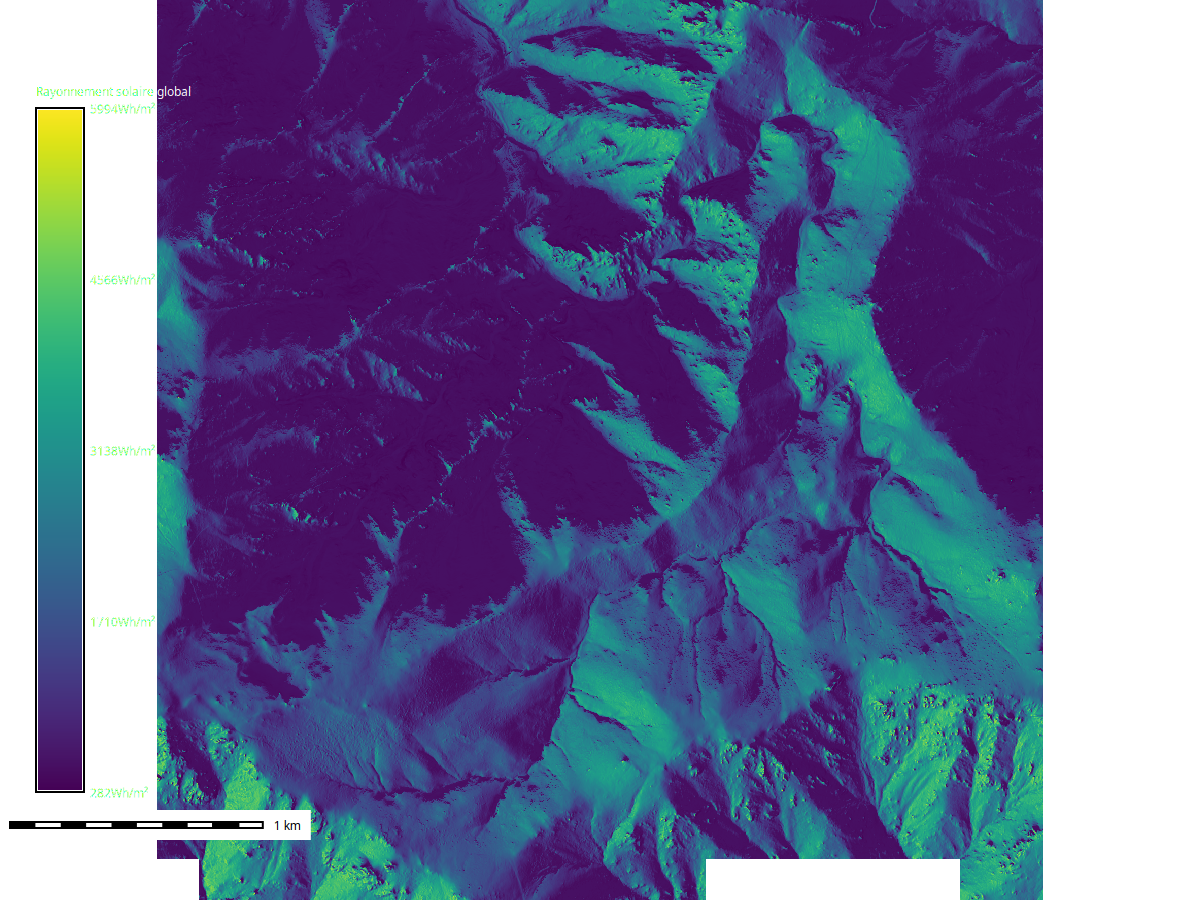

In [13]:

#test

rad_map = gj.Map(width=1200, height=900)

rad_map.d_rast(
    map="rad_004_crop"
)

rad_map.d_legend(
    raster="rad_004_crop",
    title="Rayonnement solaire global",
    units="Wh/m²",
    fontsize=12,
    color="white"
)

rad_map.d_barscale(
    units="kilometers",
    fontsize=12
)

rad_map.show()

## exporter radiations au format xarray

In [5]:
# radiations globales

import xarray as xr
import rioxarray
from pathlib import Path

data_dir = Path("/home/abernard/PHOSFORH/PhenoAnalysis/Spatial_Metrics") # à changer

rasters = []

for doy in range(1, 366):

    path = data_dir / f"rad_{doy:03d}.tif"

    da = rioxarray.open_rasterio(path).squeeze("band", drop=True)
    da = da.expand_dims(DOY=[doy])

    rasters.append(da)

# Assemblage
rad_annual = xr.concat(rasters, dim="DOY")

# Nom de la variable
rad_annual.name = "global_radiation"

# CRS
rad_annual = rad_annual.rio.write_crs(rasters[0].rio.crs)

print(rad_annual)
print("CRS :", rad_annual.rio.crs)

<xarray.DataArray 'global_radiation' (DOY: 365, y: 1773, x: 1746)> Size: 5GB
array([[[ 513.4286 ,  530.2561 ,  533.4568 , ..., 3189.052  ,
         3417.6057 , 2806.1587 ],
        [ 497.57956,  512.92694,  518.2744 , ..., 3520.6804 ,
         3847.1938 , 2446.6543 ],
        [ 523.60675,  512.56647,  503.81876, ..., 3591.436  ,
         4100.6616 , 1969.7869 ],
        ...,
        [       nan,        nan,        nan, ..., 3269.4868 ,
         2980.7288 , 3840.8462 ],
        [       nan,        nan,        nan, ..., 3107.295  ,
         3684.228  , 3273.9426 ],
        [       nan,        nan,        nan, ..., 3524.2417 ,
         3613.8684 , 2275.4944 ]],

       [[ 515.0829 ,  531.96466,  535.17566, ..., 3197.7778 ,
         3427.6958 , 2815.8652 ],
        [ 499.18283,  514.57965,  519.94434, ..., 3527.819  ,
         3857.679  , 2456.9746 ],
        [ 525.2939 ,  514.218  ,  505.44214, ..., 3598.0222 ,
         4110.217  , 1978.6715 ],
...
        [       nan,        nan,        

In [15]:
# monter un netCDF
rad_annual.to_netcdf(
    data_dir / "global_radiation_massane_MNS_365days_2mres_v2.nc",
    encoding={
        "global_radiation": {
            "zlib": True,
            "complevel": 4
        }
    }
)

In [12]:
test = xr.open_dataset(data_dir / "global_radiation_massane_MNS_365days_2mres_v2.nc")

print(test)
print(test["global_radiation"].shape)

<xarray.Dataset> Size: 5GB
Dimensions:           (DOY: 365, y: 1773, x: 1746)
Coordinates:
  * DOY               (DOY) int64 3kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
  * y                 (y) float64 14kB 6.155e+06 6.155e+06 ... 6.152e+06
  * x                 (x) float64 14kB 6.998e+05 6.998e+05 ... 7.033e+05
Data variables:
    spatial_ref       int64 8B ...
    global_radiation  (DOY, y, x) float32 5GB ...
(365, 1773, 1746)


In [6]:
for doy in range(1, 366):
    path = data_dir / f"rad_{doy:03d}.tif"

    if path.exists():
        path.unlink()

print("Fichiers rad_XXX.tif supprimés.")

Fichiers rad_XXX.tif supprimés.


## exporter suntime

In [18]:
# export suntime

import xarray as xr
import rioxarray
from pathlib import Path

data_dir = Path("/home/abernard/PHOSFORH/PhenoAnalysis/Spatial_Metrics") # à changer

rasters = []

for doy in range(1, 366):

    path = data_dir / f"sun_{doy:03d}.tif"

    da = rioxarray.open_rasterio(path).squeeze("band", drop=True)
    da = da.expand_dims(DOY=[doy])

    rasters.append(da)

# Assemblage
sun_annual = xr.concat(rasters, dim="DOY")

# Nom de la variable
sun_annual.name = "global_suntime"

# CRS
sun_annual = sun_annual.rio.write_crs(rasters[0].rio.crs)

print(sun_annual)
print("CRS :", sun_annual.rio.crs)

<xarray.DataArray 'global_suntime' (DOY: 365, y: 1773, x: 1746)> Size: 5GB
array([[[0. , 0. , 0. , ..., 4.5, 5. , 5. ],
        [0. , 0. , 0. , ..., 5. , 5. , 5. ],
        [0. , 0. , 0. , ..., 5.5, 5. , 5. ],
        ...,
        [nan, nan, nan, ..., 8. , 8. , 8. ],
        [nan, nan, nan, ..., 8. , 8. , 8. ],
        [nan, nan, nan, ..., 8. , 8. , 8. ]],

       [[0. , 0. , 0. , ..., 4.5, 5. , 5. ],
        [0. , 0. , 0. , ..., 5. , 5. , 5. ],
        [0. , 0. , 0. , ..., 5.5, 5. , 5. ],
        ...,
        [nan, nan, nan, ..., 8. , 8. , 8. ],
        [nan, nan, nan, ..., 8. , 8. , 8. ],
        [nan, nan, nan, ..., 8. , 8. , 8. ]],

       [[0. , 0. , 0. , ..., 4.5, 5. , 5. ],
        [0. , 0. , 0. , ..., 5. , 5. , 5. ],
        [0. , 0. , 0. , ..., 5.5, 5. , 5. ],
        ...,
...
        [nan, nan, nan, ..., 8. , 8. , 8. ],
        [nan, nan, nan, ..., 8. , 8. , 8. ],
        [nan, nan, nan, ..., 8. , 8. , 8. ]],

       [[0. , 0. , 0. , ..., 4.5, 5. , 5. ],
        [0. , 0. , 0.

In [20]:
# monter un netCDF
sun_annual.to_netcdf(
    data_dir / "global_suntime_massane_MNS_365days_2mres_v2.nc",
    encoding={
        "global_suntime": {
            "zlib": True,
            "complevel": 4
        }
    }
)

In [8]:
test = xr.open_dataset(data_dir / "global_suntime_massane_MNS_365days_2mres_v2.nc")

print(test)
print(test["global_suntime"].shape)

<xarray.Dataset> Size: 5GB
Dimensions:         (DOY: 365, y: 1773, x: 1746)
Coordinates:
  * DOY             (DOY) int64 3kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
  * y               (y) float64 14kB 6.155e+06 6.155e+06 ... 6.152e+06 6.152e+06
  * x               (x) float64 14kB 6.998e+05 6.998e+05 ... 7.033e+05 7.033e+05
Data variables:
    spatial_ref     int64 8B ...
    global_suntime  (DOY, y, x) float32 5GB ...
(365, 1773, 1746)


In [7]:
# supprimer les tiff individuels
for doy in range(1, 366):
    path = data_dir / f"sun_{doy:03d}.tif"

    if path.exists():
        path.unlink()

print("Fichiers sun_XXX.tif supprimés.")

Fichiers sun_XXX.tif supprimés.


## somme pour tester

In [13]:
sun_annual_sum = test["global_radiation"].sum(dim="DOY")

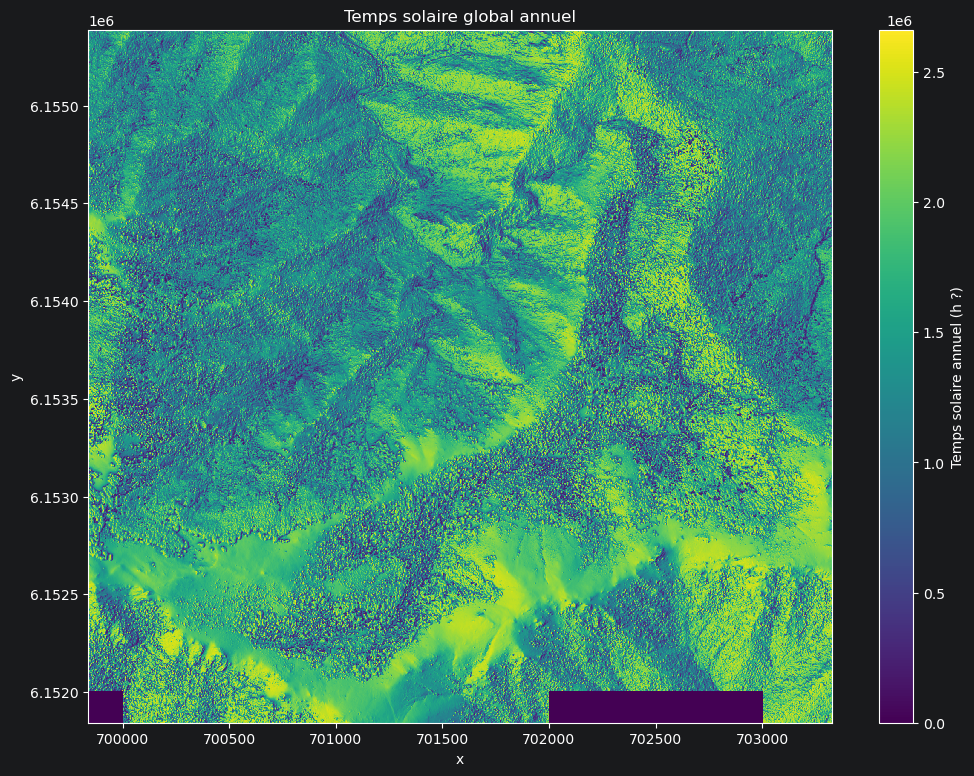

In [14]:
sun_annual_sum.plot(
    figsize=(12, 9),
    cbar_kwargs={"label": "Temps solaire annuel (h ?)"}
)

plt.title("Temps solaire global annuel")
plt.show()

In [29]:
## plot to test


sun_1day = test["global_suntime"].sel(DOY = 30)


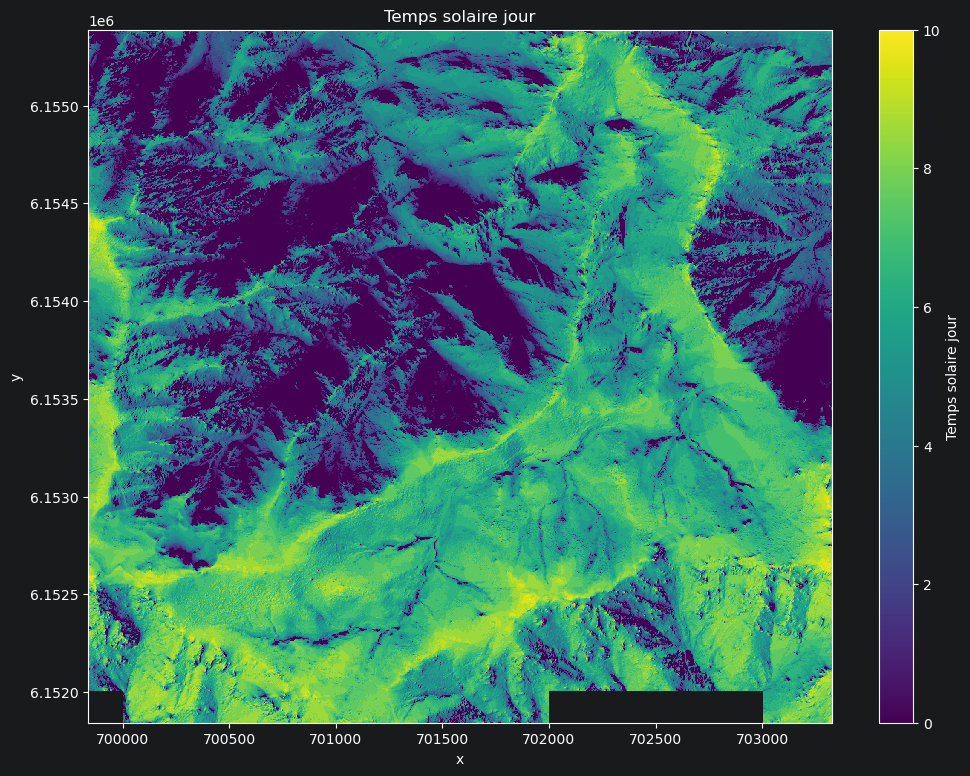

In [30]:
sun_1day.plot(
    figsize=(12, 9),
    cbar_kwargs={"label": "Temps solaire jour"}
)

plt.title("Temps solaire jour")
plt.show()